# 03 — EDNN predictive uncertainty with lead time

This notebook responds to a reviewer comment. Notebook 02 shows forecasts of ice pellets (IP) and freezing rain (FZRA) collapsing toward rain and snow as lead time increases. The reviewer asked for an analogous figure showing how the **uncertainty** changes, to support the manuscript's third main point.

**Hypothesis.** At short leads, uncertainty is high in the mixed regimes (IP, FZRA). At longer leads, forecasts drift toward the dominant classes (rain, snow), and uncertainty falls.

**Scope.** EDNN systems only (Aurora, GraphCast, WXFormer, FuXi, Pangu-Weather, GFS), on the same **common-valid sample** used in notebooks 01 and 02.

**Uncertainty measures (per case)**

| Symbol | Definition | Used in |
|---|---|---|
| $U_{tot}$ | $\sum_k \text{ale}_k + \sum_k \text{epi}_k$ (total) | Main figures |
| $U_{ale}$ | $\sum_k \text{ale}_k$ (aleatoric) | Supplement |
| $U_{epi}$ | $\sum_k \text{epi}_k$ (epistemic) | Supplement |
| $f_{epi}$ | $U_{epi} / U_{tot}$ (epistemic fraction) | Supplement |

Here $k$ runs over rain, snow, IP and FZRA.

**Figures**

1. **Main:** $U_{tot}$ vs forecast day for each observed class. This is the direct analogue of the notebook 02 collapse figure.
2. **Main or supplement:** $U_{tot}$ for observed IP and FZRA, split by the *predicted* class. This separates a **composition effect** (more cases forecast as snow or rain, which are inherently low-uncertainty) from a **within-class shift** (each forecast class itself becoming more confident). It also shows whether misses are **confidently wrong**.
3. **Supplement S1:** $U_{ale}$, $U_{epi}$ and $f_{epi}$ separately.
4. **Supplement S2:** accuracy vs $U_{tot}$ at day 1 and day 7, i.e. whether lower uncertainty still means higher accuracy at long leads.

**Inputs:** `common_valid_multimodel_predictions.parquet` (notebook 01) and the per-model `*_mping_collocations.parquet` files. The common-sample file does not carry the ale/epi fields, so they are read from the collocation files and restricted to the common (obs_id, forecast_day) keys.

## 1. Imports

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

pd.set_option("display.max_columns", 100)

## 2. Configuration

Paths and class definitions must match notebooks 01 and 02.
- `MIN_N` is the minimum number of cases for a median (or an accuracy value) to be plotted; smaller groups are masked.
- `SYSTEM_COLORS` is a colour-blind-safe palette, one colour per EDNN system.

In [5]:
# ============================================================
# OBSERVED-CLASS RULE (must match notebook 01: "modal" | "consensus")
# ============================================================
OBS_RULE = "modal"
_RULE_SUFFIX = "" if OBS_RULE == "consensus" else f"_{OBS_RULE}"

# ============================================================
# PATHS (must match notebooks 01 and 02)
# ============================================================
AI_BASE = Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
OUT = AI_BASE / f"verification_multimodel{_RULE_SUFFIX}"
FIG = Path("/glade/work/sakor/AI_NWP") / f"figures{_RULE_SUFFIX}"
FIG.mkdir(parents=True, exist_ok=True)

COMMON_FILE = OUT / "common_valid_multimodel_predictions.parquet"
def collocation_file(model):
    return OUT / f"{model.lower().replace('-', '_')}_mping_collocations.parquet"

# ============================================================
# CLASSES AND EDNN OUTPUT FIELDS
# ============================================================
CLASS_NAMES = {0: "Rain", 1: "Snow", 2: "Ice Pellet", 3: "Freezing Rain"}
CLASS_ORDER = ["Rain", "Snow", "Ice Pellet", "Freezing Rain"]
FRZR_IP_CLASSES = ["Ice Pellet", "Freezing Rain"]

ALE_COLS = ["ML_rain_ale", "ML_snow_ale", "ML_icep_ale", "ML_frzr_ale"]   # same class order
EPI_COLS = ["ML_rain_epi", "ML_snow_epi", "ML_icep_epi", "ML_frzr_epi"]

# ============================================================
# EDNN SYSTEMS
# ============================================================
EDNN_MODELS = ["Aurora", "GraphCast", "WXFormer", "FuXi", "Pangu-Weather", "GFS"]
SYSTEM_LABEL = {m: (f"{m} (EDNN)" if m == "GFS" else m) for m in EDNN_MODELS}
SYSTEM_COLORS = {
    "Aurora": "#0072B2", "GraphCast": "#E69F00", "WXFormer": "#009E73",
    "FuXi": "#CC79A7", "Pangu-Weather": "#D55E00", "GFS": "#000000",
}
CLASS_COLORS = {                                  # same as notebook 02
    "Rain": "#009E73", "Snow": "#56B4E9",
    "Ice Pellet": "#CC79A7", "Freezing Rain": "#D55E00",
}

DAYS = np.arange(1, 8)
MIN_N = 30

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 7.5,
    "axes.titlesize": 8.5, "axes.labelsize": 7.5,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
LETTERS = "abcdefghijklmnopqrstuvwxyz"

## 3. Load EDNN uncertainty on the common-valid sample

For each EDNN system, this reads the collocation file and keeps only the (obs_id, forecast_day) pairs in the common-valid sample.

Two checks run on each system:
- every common pair is found exactly once, and
- the collocated `ML_ptype` matches the EDNN `pred_code` in the common-sample file, so the uncertainty rows line up with the predictions scored in notebooks 01 and 02.

In [6]:
if not COMMON_FILE.exists():
    raise FileNotFoundError(f"{COMMON_FILE} not found — run notebook 01 first.")

common = pd.read_parquet(COMMON_FILE, columns=["obs_id", "forecast_day", "System", "pred_code"])
keys = common[["obs_id", "forecast_day"]].drop_duplicates()
print(f"Common obs/day pairs: {len(keys):,}")

frames = []
for model in EDNN_MODELS:
    cols = ["obs_id", "forecast_day", "lead_hour", "obs_class", "ML_ptype"] + ALE_COLS + EPI_COLS
    d = pd.read_parquet(collocation_file(model), columns=cols)
    d = d.merge(keys, on=["obs_id", "forecast_day"], how="inner")
    assert len(d) == len(keys), f"{model}: {len(d):,} rows vs {len(keys):,} common keys"
    assert not d.duplicated(["obs_id", "forecast_day"]).any(), f"{model}: duplicate keys"

    ref = common[common.System == f"{model} — EDNN"][["obs_id", "forecast_day", "pred_code"]]
    chk = d.merge(ref, on=["obs_id", "forecast_day"])
    assert (chk.ML_ptype.astype(int) == chk.pred_code).all(), f"{model}: ML_ptype ≠ common pred_code"

    d["Model"] = model
    frames.append(d)
    print(f"  {model:14s} {len(d):,} rows")

unc = pd.concat(frames, ignore_index=True)
unc["pred_class"] = unc.ML_ptype.astype(int).map(CLASS_NAMES)
unc["correct"] = unc.pred_class == unc.obs_class

Common obs/day pairs: 213,860
  Aurora         213,860 rows
  GraphCast      213,860 rows
  WXFormer       213,860 rows
  FuXi           213,860 rows
  Pangu-Weather  213,860 rows
  GFS            213,860 rows


## 4. Uncertainty measures

For each case:
- $U_{ale} = \sum_k \text{ale}_k$
- $U_{epi} = \sum_k \text{epi}_k$
- $U_{tot} = U_{ale} + U_{epi}$
- $f_{epi} = U_{epi} / U_{tot}$

The columns are named `U_ale`, `U_epi`, `U_tot` and `f_epi`. The name `T` is avoided because it clashes with `DataFrame.T`.

In [7]:
unc["U_ale"] = unc[ALE_COLS].sum(axis=1)
unc["U_epi"] = unc[EPI_COLS].sum(axis=1)
unc["U_tot"] = unc.U_ale + unc.U_epi
unc["f_epi"] = np.where(unc.U_tot > 0, unc.U_epi / unc.U_tot, np.nan)

n_bad = unc[ALE_COLS + EPI_COLS].isna().any(axis=1).sum()
print(f"Rows with any missing ale/epi field: {n_bad:,}")
display(unc.groupby("Model")[["U_ale", "U_epi", "U_tot", "f_epi"]]
           .describe(percentiles=[.5]).round(4))

Rows with any missing ale/epi field: 1,828


U_ale                                             U_epi  \
                  count    mean     std     min     50%     max     count   
Model                                                                       
Aurora         213860.0  0.1082  0.1675  0.0029  0.0245  0.6939  213860.0   
FuXi           213860.0  0.0960  0.1576  0.0000  0.0213  0.6940  213860.0   
GFS            213860.0  0.1074  0.1657  0.0028  0.0244  0.6916  213860.0   
GraphCast      213860.0  0.1056  0.1643  0.0030  0.0241  0.6912  213860.0   
Pangu-Weather  213860.0  0.1039  0.1632  0.0030  0.0238  0.6876  213860.0   
WXFormer       213860.0  0.1079  0.1655  0.0000  0.0255  0.6921  213860.0   

                                                       U_tot                  \
                 mean     std  min     50%     max     count    mean     std   
Model                                                                          
Aurora         0.0058  0.0128  0.0  0.0001  0.1500  213860.0  0.1140  0.1798   
FuXi           0.0049  0.0116  0.0  0.0001  0.1312  213860.0  0.1009  0.1687   
GFS            0.0057  0.0126  0.0  0.0001  0.1320  213860.0  0.1131  0.1777   
GraphCast      0.0056  0.0123  0.0  0.0001  0.1500  213860.0  0.1112  0.1761   
Pangu-Weather  0.0055  0.0124  0.0  0.0001  0.1495  213860.0  0.1094  0.1751   
WXFormer       0.0057  0.0124  0.0  0.0001  0.1133  213860.0  0.1136  0.1774   

                                          f_epi                          \
                  min     50%     max     count    mean     std     min   
Model                                                                     
Aurora         0.0029  0.0246  0.7500  213860.0  0.0161  0.0230  0.0005   
FuXi           0.0000  0.0214  0.7485  212278.0  0.0143  0.0214  0.0005   
GFS            0.0028  0.0245  0.7462  213860.0  0.0160  0.0229  0.0005   
GraphCast      0.0030  0.0242  0.7500  213860.0  0.0157  0.0225  0.0005   
Pangu-Weather  0.0030  0.0239  0.7500  213860.0  0.0156  0.0226  0.0005   
WXFormer       0.0000  0.0256  0.7454  213614.0  0.0161  0.0226  0.0005   

                               
                  50%     max  
Model                          
Aurora         0.0041  0.2000  
FuXi           0.0036  0.1771  
GFS            0.0041  0.1785  
GraphCast      0.0041  0.2000  
Pangu-Weather  0.0040  0.1993  
WXFormer       0.0043  0.1555

## 6. Summary tables

These tables give the median and interquartile range of each measure by system, observed class and forecast day. They are saved as CSV for quoting numbers in the text.

A second table breaks observed IP and FZRA down by predicted class; it supports Figure 2.

In [8]:
MEASURES = ["U_tot", "U_ale", "U_epi", "f_epi"]

def qstats(df, by):
    rows = []
    for key, g in df.groupby(by):
        r = dict(zip(by, key if isinstance(key, tuple) else (key,)))
        r["N"] = len(g)
        for m in MEASURES:
            q = g[m].quantile([.25, .5, .75])
            r[f"{m}_q25"], r[f"{m}_med"], r[f"{m}_q75"] = q.values
        rows.append(r)
    return pd.DataFrame(rows)

stats_obs = qstats(unc, ["Model", "obs_class", "forecast_day"])
stats_obs.to_csv(OUT / "ednn_uncertainty_by_obsclass_day.csv", index=False)

stats_obs_pred = qstats(unc[unc.obs_class.isin(FRZR_IP_CLASSES)],
                        ["Model", "obs_class", "pred_class", "forecast_day"])
stats_obs_pred.to_csv(OUT / "ednn_uncertainty_ip_fzra_by_predclass_day.csv", index=False)

# compact day-1 vs day-7 table of median total uncertainty
d17 = (stats_obs[stats_obs.forecast_day.isin([1, 7])]
       .pivot_table(index=["obs_class", "Model"], columns="forecast_day", values="U_tot_med"))
d17.columns = ["U_tot d1", "U_tot d7"]
d17["Δ"] = d17["U_tot d7"] - d17["U_tot d1"]
d17 = d17.reindex(pd.MultiIndex.from_product([CLASS_ORDER, EDNN_MODELS],
                                             names=["obs_class", "Model"]))
d17.to_csv(OUT / "ednn_uncertainty_day1_vs_day7.csv")
display(d17.round(3))

U_tot d1  U_tot d7      Δ
obs_class     Model                                   
Rain          Aurora            0.011     0.013  0.002
              GraphCast         0.011     0.014  0.002
              WXFormer          0.013     0.017  0.004
              FuXi              0.012     0.016  0.003
              Pangu-Weather     0.012     0.013  0.001
              GFS               0.012     0.016  0.003
Snow          Aurora            0.027     0.031  0.004
              GraphCast         0.026     0.032  0.005
              WXFormer          0.027     0.030  0.003
              FuXi              0.027     0.016 -0.011
              Pangu-Weather     0.026     0.028  0.003
              GFS               0.026     0.026  0.000
Ice Pellet    Aurora            0.404     0.179 -0.224
              GraphCast         0.390     0.077 -0.312
              WXFormer          0.269     0.043 -0.226
              FuXi              0.337     0.020 -0.318
              Pangu-Weather     0.359     0.036 -0.323
              GFS               0.373     0.041 -0.331
Freezing Rain Aurora            0.420     0.229 -0.191
              GraphCast         0.398     0.127 -0.271
              WXFormer          0.402     0.057 -0.344
              FuXi              0.413     0.029 -0.384
              Pangu-Weather     0.407     0.076 -0.332
              GFS               0.475     0.088 -0.388

## 7. Figure 1 — total uncertainty by observed class and lead time

This is the analogue of the notebook 02 collapse figure.
- One panel per observed class; all panels share the same y-axis so the classes can be compared directly.
- Each line is the median $U_{tot}$ for one EDNN system; the shading is its interquartile range.

**Expected if the hypothesis holds:** IP and FZRA start high and decline with lead, while rain and snow stay low and roughly flat.

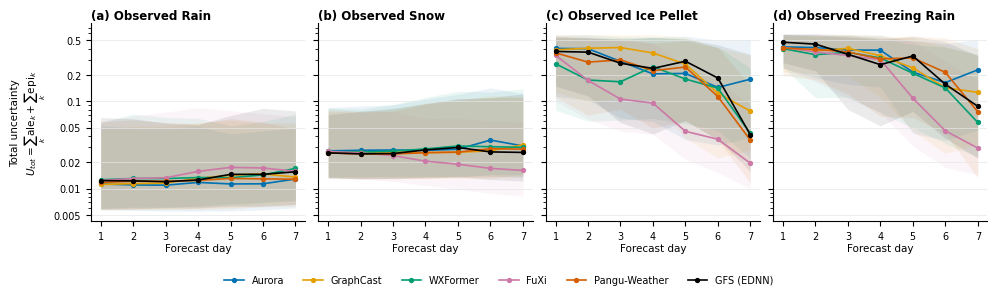

In [9]:
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter

YSCALE = "log"     # "log" (recommended: rain/snow and IP/FZRA differ by ~10x) or "linear"

fig, axes = plt.subplots(1, len(CLASS_ORDER), figsize=(10.0, 2.9), sharey=True)
n_by_cls = unc[unc.Model == EDNN_MODELS[0]].groupby(["obs_class", "forecast_day"]).size()

# y-limits from ALL plotted data (medians and IQR, every class and system)
plotted = stats_obs[stats_obs.Model.isin(EDNN_MODELS)]
y_hi = plotted.U_tot_q75.max()
y_lo = plotted.loc[plotted.U_tot_q25 > 0, "U_tot_q25"].min()

for c, cls in enumerate(CLASS_ORDER):
    ax = axes[c]
    for m in EDNN_MODELS:
        s = (stats_obs[(stats_obs.Model == m) & (stats_obs.obs_class == cls)]
             .set_index("forecast_day").reindex(DAYS))
        q25 = s.U_tot_q25.clip(lower=y_lo) if YSCALE == "log" else s.U_tot_q25
        ax.fill_between(DAYS, q25, s.U_tot_q75,
                        color=SYSTEM_COLORS[m], alpha=0.08, linewidth=0)
        ax.plot(DAYS, s.U_tot_med, marker="o", ms=2.8, lw=1.2,
                color=SYSTEM_COLORS[m], label=SYSTEM_LABEL[m])
    n = n_by_cls.loc[cls]
    ax.set_title(f"({LETTERS[c]}) Observed {cls}", loc="left", fontweight="bold", pad=3)
    # ax.text(0.98, 0.97, f"N = {n.min():,}–{n.max():,} per forecast day", transform=ax.transAxes,
    #         ha="right", va="top", fontsize=6.5, color="#444444",
    #         bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
    ax.set_xticks(DAYS)
    ax.set_xlabel("Forecast day", labelpad=2)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.grid(axis="y", which="major", color="#e6e6e6", linewidth=0.5)

# set scale/limits ONCE, after all data are drawn (shared y-axis)
if YSCALE == "log":
    axes[0].set_yscale("log")
    axes[0].set_ylim(y_lo / 1.3, y_hi * 1.3)
    axes[0].yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    axes[0].yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}"))
    axes[0].yaxis.set_minor_formatter(NullFormatter())
else:
    axes[0].set_ylim(0, y_hi * 1.05)

axes[0].set_ylabel("Total uncertainty\n" r"$U_{tot}=\sum_k$ale$_k+\sum_k$epi$_k$")

h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=len(EDNN_MODELS), frameon=False,
           fontsize=7, bbox_to_anchor=(0.5, -0.02))
# fig.text(0.5, -0.07, "Lines: median; shading: interquartile range"
#          + ("; log y-axis." if YSCALE == "log" else "."),
#          ha="center", fontsize=6.5, color="#444444")
fig.tight_layout(rect=(0, 0.08, 1, 1), w_pad=0.8)
fig.savefig(FIG / "ednn_total_uncertainty_by_obsclass_leadtime.pdf", dpi=400, bbox_inches="tight")
plt.show()

## 9. Supplementary Figure S1 — aleatoric, epistemic and epistemic fraction

This has the same layout as Figure 1, but each row is one component:
- **Row 1:** $U_{ale}$
- **Row 2:** $U_{epi}$
- **Row 3:** $f_{epi} = U_{epi}/U_{tot}$

Each row has its own y-axis. If the Section 5 check passes, $U_{ale}$ and $U_{epi}$ both scale with $U_{tot}$, and $f_{epi} = 1/(S+1)$ isolates the evidence strength. A rising $f_{epi}$ with lead would mean the network has relatively less evidence for long-lead inputs, even when its probabilities are sharp.

If $U_{epi}$ spans several orders of magnitude, set `EPI_LOG = True`.

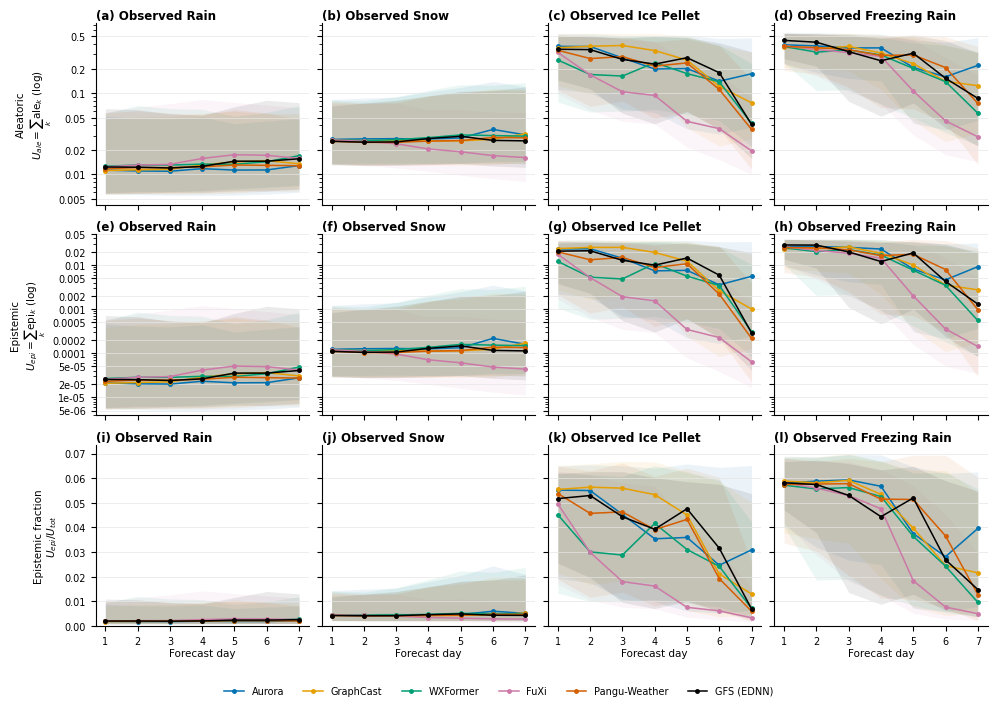

In [10]:
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter

# (measure, y-label, scale). U_ale and U_epi scale with U_tot, so they show the same
# ~10x rain/snow vs IP/FZRA contrast -> log. f_epi is a bounded fraction -> linear.
ROWS_S1 = [("U_ale", "Aleatoric\n" r"$U_{ale}=\sum_k$ale$_k$", "log"),
           ("U_epi", "Epistemic\n" r"$U_{epi}=\sum_k$epi$_k$", "log"),
           ("f_epi", "Epistemic fraction\n" r"$U_{epi}/U_{tot}$", "linear")]

def set_row_scale(ax, meas, scale):
    """Set y-scale and limits for a whole (shared) row from ALL plotted data."""
    plotted = stats_obs[stats_obs.Model.isin(EDNN_MODELS)]
    hi = plotted[f"{meas}_q75"].max()
    lo = plotted.loc[plotted[f"{meas}_q25"] > 0, f"{meas}_q25"].min()
    if scale == "log":
        ax.set_yscale("log")
        ax.set_ylim(lo / 1.3, hi * 1.3)
        ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}"))
        ax.yaxis.set_minor_formatter(NullFormatter())
    else:
        ax.set_ylim(0, hi * 1.05)
    return lo

fig, axes = plt.subplots(len(ROWS_S1), len(CLASS_ORDER), figsize=(10.0, 7.0),
                         sharex=True, sharey="row")
for r, (meas, ylab, scale) in enumerate(ROWS_S1):
    lo = set_row_scale(axes[r, 0], meas, scale)      # sharey="row" -> applies to whole row
    for c, cls in enumerate(CLASS_ORDER):
        ax = axes[r, c]
        for m in EDNN_MODELS:
            s = (stats_obs[(stats_obs.Model == m) & (stats_obs.obs_class == cls)]
                 .set_index("forecast_day").reindex(DAYS))
            q25 = s[f"{meas}_q25"].clip(lower=lo) if scale == "log" else s[f"{meas}_q25"]
            ax.fill_between(DAYS, q25, s[f"{meas}_q75"],
                            color=SYSTEM_COLORS[m], alpha=0.08, linewidth=0)
            ax.plot(DAYS, s[f"{meas}_med"], marker="o", ms=2.5, lw=1.1,
                    color=SYSTEM_COLORS[m], label=SYSTEM_LABEL[m])
        ax.set_title(f"({LETTERS[r * len(CLASS_ORDER) + c]}) Observed {cls}",
                     loc="left", fontweight="bold", pad=3)
        ax.set_xticks(DAYS)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
        ax.grid(axis="y", which="major", color="#e6e6e6", linewidth=0.5)
        if r == len(ROWS_S1) - 1:
            ax.set_xlabel("Forecast day", labelpad=2)
        if c == 0:
            ax.set_ylabel(ylab + (" (log)" if scale == "log" else ""), labelpad=3)
    set_row_scale(axes[r, 0], meas, scale)           # re-assert limits after drawing

h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=len(EDNN_MODELS), frameon=False,
           fontsize=7, bbox_to_anchor=(0.5, -0.01))
# fig.text(0.5, -0.03, "Lines: median; shading: interquartile range. "
#          "Rows (a–d) and (e–h): log y-axis; row (i–l): linear.",
#          ha="center", fontsize=6.5, color="#444444")
fig.tight_layout(rect=(0, 0.04, 1, 1), w_pad=0.8, h_pad=1.0)
fig.savefig(FIG / "ednn_uncertainty_components_supp.pdf", dpi=400, bbox_inches="tight")
plt.show()